# HW3 Image Classification

In [1]:
%env CUDA_VISIBLE_DEVICES=0
%env OMP_NUM_THREADS=4

env: CUDA_VISIBLE_DEVICES=0
env: OMP_NUM_THREADS=4


In [2]:
!nvidia-smi

Fri Oct 23 08:01:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|


|   0  NVIDIA GeForce RTX 4090        On  |   00000000:27:00.0 Off |                  Off |
| 31%   35C    P8             17W /  450W |    5043MiB /  24564MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------------------+----------------------+
|   1  NVIDIA GeForce RTX 4090        On  |   00000000:38:00.0 Off |                  Off |
| 32%   33C    P8             21W /  450W |    4355MiB /  24564MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------------------+----------------------+
|   2  NVIDIA GeForce RTX 4090        On  |   00000000:A8:00.0 Off |                  Off |
| 30%   31C    P2             54W /  450W |   23290MiB /  24564MiB |      0%      Default |
|                                         |                        |            

# Import Packages

In [3]:
_exp_name = "hw3_final_cnn"

In [4]:
# Import necessary packages.
import numpy as np
import pandas as pd
import torch
import os
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
# "ConcatDataset" and "Subset" are possibly useful when doing semi-supervised learning.
from torch.utils.data import ConcatDataset, DataLoader, Subset, Dataset
from torchvision.datasets import DatasetFolder, VisionDataset
# This is for the progress bar.
from tqdm.auto import tqdm
import random

In [5]:
myseed = 6666  # set a random seed for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
np.random.seed(myseed)
torch.manual_seed(myseed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(myseed)

# Transforms
Torchvision provides lots of useful utilities for image preprocessing, data *wrapping* as well as data augmentation.

Please refer to PyTorch official website for details about different transforms.

In [6]:
# Normally, We don't need augmentations in testing and validation.
# All we need here is to resize the PIL image and transform it into Tensor.
test_tfm = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]), # Channel 正規化
])

# However, it is also possible to use augmentation in the testing phase.
# You may use train_tfm to produce a variety of images and then test using ensemble methods
train_tfm = transforms.Compose([
    transforms.RandomResizedCrop(128, scale=(0.4, 1.0)), # 隨機裁切部分區域並還原成特定大小
    transforms.RandomHorizontalFlip(), # 左右翻轉
    transforms.TrivialAugmentWide(), # 從各種操作中挑一種，隨機強度
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]), # Channel 正規化
    transforms.RandomErasing(p=0.25), # 隨機隱藏部分區域
])

# Datasets
The data is labelled by the name, so we load images and label while calling '__getitem__'

In [7]:
class FoodDataset(Dataset):

    def __init__(self,path,tfm=test_tfm,files = None):
        super(FoodDataset).__init__()
        self.path = path
        self.files = sorted([os.path.join(path,x) for x in os.listdir(path) if x.endswith(".jpg")])
        if files != None:
            self.files = files

        self.transform = tfm

    def __len__(self):
        return len(self.files)

    def __getitem__(self,idx):
        fname = self.files[idx]
        im = Image.open(fname)
        im = self.transform(im)

        try:
            label = int(fname.split("/")[-1].split("_")[0])
        except:
            label = -1 # test has no label

        return im,label

# Model

In [8]:
class Classifier(nn.Module):
    def __init__(self):
        super(Classifier, self).__init__()
        # torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
        # torch.nn.MaxPool2d(kernel_size, stride, padding)
        # input 維度 [3, 128, 128]
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1),  # [64, 128, 128]
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, 1, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [64, 64, 64]

            nn.Conv2d(64, 128, 3, 1, 1), # [128, 64, 64]
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, 1, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [128, 32, 32]

            nn.Conv2d(128, 256, 3, 1, 1), # [256, 32, 32]
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, 1, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [256, 16, 16]

            nn.Conv2d(256, 512, 3, 1, 1), # [512, 16, 16]
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, 3, 1, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),       # [512, 8, 8]

            nn.Conv2d(512, 512, 3, 1, 1), # [512, 8, 8]
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, 3, 1, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),       # [512, 4, 4]

        )
        self.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(512*4*4, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 11)
        )

    def forward(self, x):
        out = self.cnn(x)
        out = out.view(out.size()[0], -1)
        return self.fc(out)

# Configurations

In [9]:
# "cuda" only when GPUs are available.
device = "cuda" if torch.cuda.is_available() else "cpu"

# Initialize a model, and put it on the device specified.
model = Classifier().to(device)

# The number of batch size.
batch_size = 128

# The number of training epochs.
n_epochs = 150

# If no improvement in 'patience' epochs, early stop.
patience = 40

# For the classification task, we use cross-entropy as the measurement of performance.
criterion = nn.CrossEntropyLoss()

# Initialize optimizer, you may fine-tune some hyperparameters such as learning rate on your own.
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

# Dataloader

In [10]:
# Construct train and valid datasets.
# The argument "loader" tells how torchvision reads the data.
train_set = FoodDataset("./food11/training", tfm=train_tfm)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
valid_set = FoodDataset("./food11/validation", tfm=test_tfm)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

# Start Training

In [11]:
# Initialize trackers, these are not parameters and should not be changed
stale = 0
best_acc = 0
history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}

for epoch in range(n_epochs):

    # ---------- Training ----------
    # Make sure the model is in train mode before training.
    model.train()

    # These are used to record information in training.
    train_loss = []
    train_accs = []

    for batch in tqdm(train_loader):

        # A batch consists of image data and corresponding labels.
        imgs, labels = batch
        #imgs = imgs.half()
        #print(imgs.shape,labels.shape)

        # Forward the data. (Make sure data and model are on the same device.)
        logits = model(imgs.to(device))

        # Calculate the cross-entropy loss.
        # We don't need to apply softmax before computing cross-entropy as it is done automatically.
        loss = criterion(logits, labels.to(device))

        # Gradients stored in the parameters in the previous step should be cleared out first.
        optimizer.zero_grad()

        # Compute the gradients for parameters.
        loss.backward()

        # Clip the gradient norms for stable training.
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=10)

        # Update the parameters with computed gradients.
        optimizer.step()

        # Compute the accuracy for current batch.
        acc = (logits.argmax(dim=-1) == labels.to(device)).float().mean()

        # Record the loss and accuracy.
        train_loss.append(loss.item())
        train_accs.append(acc)

    train_loss = sum(train_loss) / len(train_loss)
    train_acc = sum(train_accs) / len(train_accs)

    scheduler.step()

    # Print the information.
    print(f"[ Train | {epoch + 1:03d}/{n_epochs:03d} ] loss = {train_loss:.5f}, acc = {train_acc:.5f}")

    # ---------- Validation ----------
    # Make sure the model is in eval mode so that some modules like dropout are disabled and work normally.
    model.eval()

    # These are used to record information in validation.
    valid_loss = []
    valid_accs = []

    # Iterate the validation set by batches.
    for batch in tqdm(valid_loader):

        # A batch consists of image data and corresponding labels.
        imgs, labels = batch
        #imgs = imgs.half()

        # We don't need gradient in validation.
        # Using torch.no_grad() accelerates the forward process.
        with torch.no_grad():
            logits = model(imgs.to(device))

        # We can still compute the loss (but not the gradient).
        loss = criterion(logits, labels.to(device))

        # Compute the accuracy for current batch.
        acc = (logits.argmax(dim=-1) == labels.to(device)).float().mean()

        # Record the loss and accuracy.
        valid_loss.append(loss.item())
        valid_accs.append(acc)
        #break

    # The average loss and accuracy for entire validation set is the average of the recorded values.
    valid_loss = sum(valid_loss) / len(valid_loss)
    valid_acc = sum(valid_accs) / len(valid_accs)

    # Print the information.
    print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f}")

    history["train_loss"].append(train_loss)
    history["valid_loss"].append(valid_loss)
    history["train_acc"].append(train_acc.item())
    history["valid_acc"].append(valid_acc.item())

    # update logs
    if valid_acc > best_acc:
        with open(f"./{_exp_name}_log.txt","a"):
            print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f} -> best")
    else:
        with open(f"./{_exp_name}_log.txt","a"):
            print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f}")


    # save models
    if valid_acc > best_acc:
        print(f"Best model found at epoch {epoch}, saving model")
        torch.save(model.state_dict(), f"{_exp_name}_best.ckpt") # only save best to prevent output memory exceed error
        best_acc = valid_acc
        stale = 0
    else:
        stale += 1
        if stale > patience:
            print(f"No improvment {patience} consecutive epochs, early stopping")
            break

  0%|          | 0/78 [00:00<?, ?it/s]

[ Train | 001/150 ] loss = 2.36986, acc = 0.16372


  0%|          | 0/27 [00:00<?, ?it/s]

[ Valid | 001/150 ] loss = 2.20524, acc = 0.18547
[ Valid | 001/150 ] loss = 2.20524, acc = 0.18547 -> best
Best model found at epoch 0, saving model


  0%|          | 0/78 [00:00<?, ?it/s]

[ Train | 002/150 ] loss = 2.26582, acc = 0.17784


... (590 outputs left out)

  0%|          | 0/78 [00:00<?, ?it/s]

[ Train | 150/150 ] loss = 0.55565, acc = 0.82196


  0%|          | 0/27 [00:00<?, ?it/s]

[ Valid | 150/150 ] loss = 0.59952, acc = 0.81712
[ Valid | 150/150 ] loss = 0.59952, acc = 0.81712


In [12]:
correct, total = 0, 0
model.eval()
with torch.no_grad():
    for imgs, lbls in valid_loader:
        preds = model(imgs.to(device)).argmax(dim=-1).cpu()
        correct += (preds == lbls).sum().item()
        total += len(lbls)
print(f"Accuracy: {correct / total}")

Accuracy: 0.8163265306122449


# Dataloader for test

In [13]:
# Construct test datasets.
# The argument "loader" tells how torchvision reads the data.
test_set = FoodDataset("./food11/test", tfm=test_tfm)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

# Testing and generate prediction CSV

In [14]:
model_best = Classifier().to(device)
model_best.load_state_dict(torch.load(f"{_exp_name}_best.ckpt"))
model_best.eval()
prediction = []
with torch.no_grad():
    for data,_ in tqdm(test_loader):
        data = data.to(device)
        test_pred = model_best(data).softmax(-1) + model_best(torch.flip(data, dims=[3])).softmax(-1) # TTA: 原圖 + 左右翻轉
        test_label = np.argmax(test_pred.cpu().data.numpy(), axis=1)
        prediction += test_label.squeeze().tolist()

  0%|          | 0/27 [00:00<?, ?it/s]

In [15]:
# create test csv
def pad4(i):
    return "0"*(4-len(str(i)))+str(i)
df = pd.DataFrame()
df["Id"] = [pad4(i) for i in range(len(test_set))]
df["Category"] = prediction
df.to_csv("submission.csv",index = False)

# Q2. Visual Representations Implementation
## Visualize the learned visual representations of the CNN model on the validation set by implementing t-SNE (t-distributed Stochastic Neighbor Embedding) on the output of both top & mid layers (You need to submit 2 images).


In [16]:
import torch
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib.cm as cm
import torch.nn as nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load the trained model
model = Classifier().to(device)
state_dict = torch.load(f"{_exp_name}_best.ckpt")
model.load_state_dict(state_dict)
model.eval()

print(model)

Classifier(
  (cnn): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 256, 


  0%|                                                                                                                    | 0/54 [00:00<?, ?it/s]


  2%|██                                                                                                          | 1/54 [00:00<00:08,  6.11it/s]


  4%|████                                                                                                        | 2/54 [00:00<00:08,  6.33it/s]


  6%|██████                                                                                                      | 3/54 [00:00<00:07,  6.88it/s]


  7%|████████                                                                                                    | 4/54 [00:00<00:07,  7.06it/s]


  9%|██████████                                                                                                  | 5/54 [00:00<00:06,  7.27it/s]

... (46 outputs left out)


 96%|███████████████████████████████████████████████████████████████████████████████████████████████████████    | 52/54 [00:13<00:00,  3.95it/s]


 98%|█████████████████████████████████████████████████████████████████████████████████████████████████████████  | 53/54 [00:14<00:00,  4.18it/s]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:14<00:00,  4.72it/s]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:14<00:00,  3.80it/s]

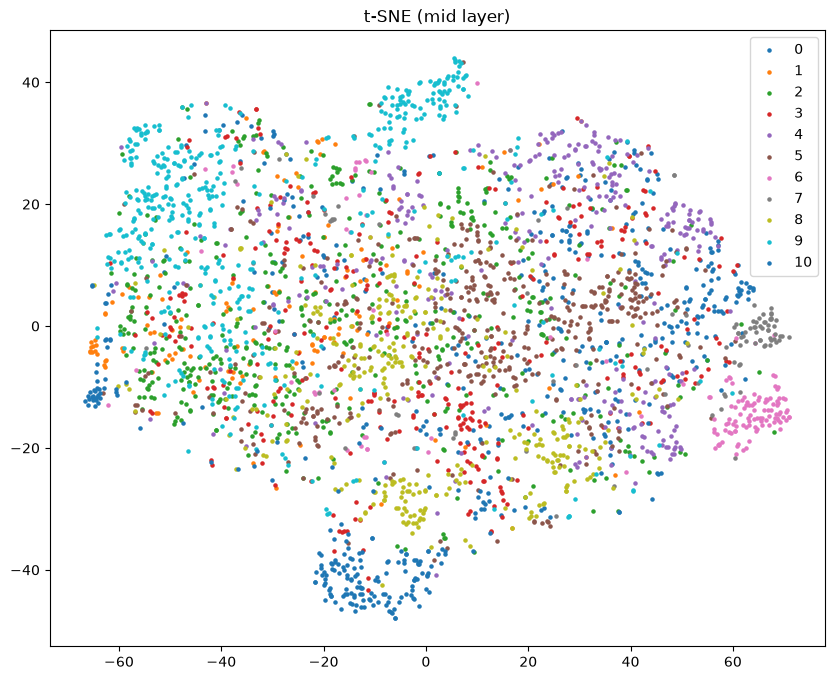

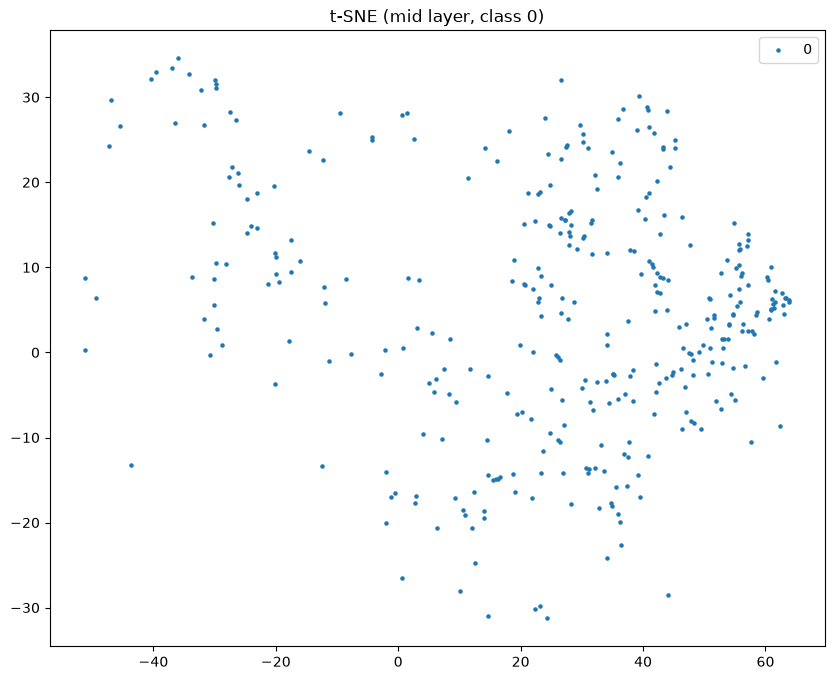


  0%|                                                                                                                    | 0/54 [00:00<?, ?it/s]


  2%|██                                                                                                          | 1/54 [00:00<00:09,  5.49it/s]


  4%|████                                                                                                        | 2/54 [00:00<00:11,  4.51it/s]


  6%|██████                                                                                                      | 3/54 [00:00<00:12,  4.23it/s]


  7%|████████                                                                                                    | 4/54 [00:01<00:18,  2.73it/s]


  9%|██████████                                                                                                  | 5/54 [00:01<00:15,  3.08it/s]

... (46 outputs left out)


 96%|███████████████████████████████████████████████████████████████████████████████████████████████████████    | 52/54 [00:14<00:00,  4.67it/s]


 98%|█████████████████████████████████████████████████████████████████████████████████████████████████████████  | 53/54 [00:14<00:00,  4.88it/s]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:14<00:00,  5.75it/s]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:14<00:00,  3.74it/s]

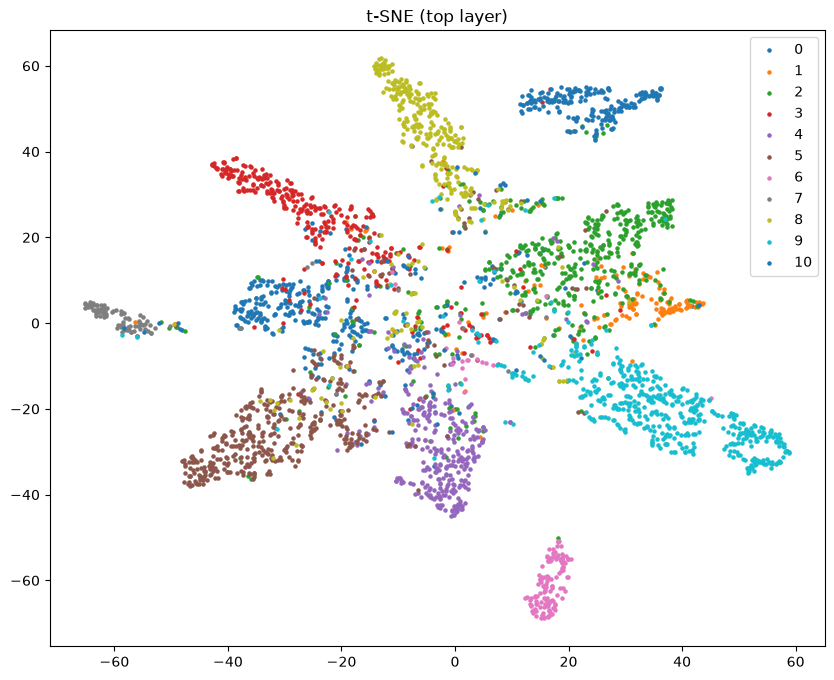

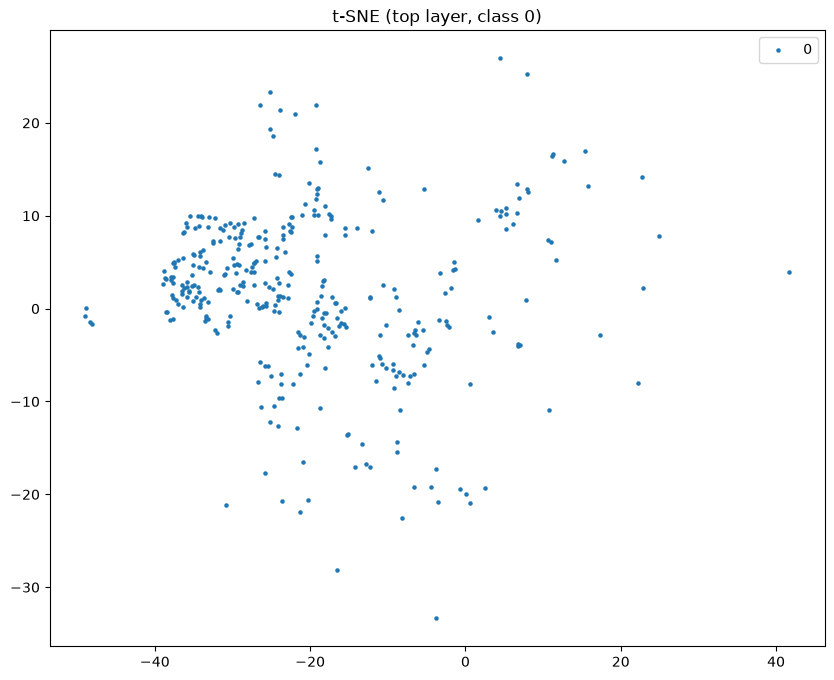

In [17]:
# Load the vaildation set defined by TA
valid_set = FoodDataset("./food11/validation", tfm=test_tfm)
valid_loader = DataLoader(valid_set, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

from sklearn.decomposition import PCA

# mid: output of 3rd conv block (cnn[:20] -> [B, 256, 32, 32]), global-average-pooled to [B, 256]
# top: penultimate fc layer (fc[:-1] -> [B, 512])
index = 20
def extract(layer):
    features, labels = [], []
    for imgs, lbls in tqdm(valid_loader):
        with torch.no_grad():
            x = imgs.to(device)
            if layer == "mid":
                x = model.cnn[:index](x).mean(dim=(2, 3))
            else:
                x = model.cnn(x).flatten(1)
                x = model.fc[:-1](x)
        features.append(x.cpu().numpy())
        labels.append(lbls.numpy())
    return np.concatenate(features), np.concatenate(labels)

for layer in ["mid", "top"]:
    features, labels = extract(layer)
    features = PCA(n_components=50, random_state=42).fit_transform(features)
    features_tsne = TSNE(n_components=2, init='pca', random_state=42).fit_transform(features)

    plt.figure(figsize=(10, 8))
    for label in np.unique(labels):
        plt.scatter(features_tsne[labels == label, 0], features_tsne[labels == label, 1], label=label, s=5)
    plt.legend()
    plt.title(f"t-SNE ({layer} layer)")
    plt.savefig(f"all_6_{layer}.png", bbox_inches="tight", dpi=300)
    plt.show()

    plt.figure(figsize=(10, 8))
    selected_labels = [0]
    for label in selected_labels:
        mask = labels == label
        plt.scatter(features_tsne[mask, 0], features_tsne[mask, 1], label=label, s=5)
    plt.legend()
    plt.title(f"t-SNE ({layer} layer, class 0)")
    plt.savefig(f"class_6_{layer}.png", bbox_inches="tight", dpi=300)
    plt.show()


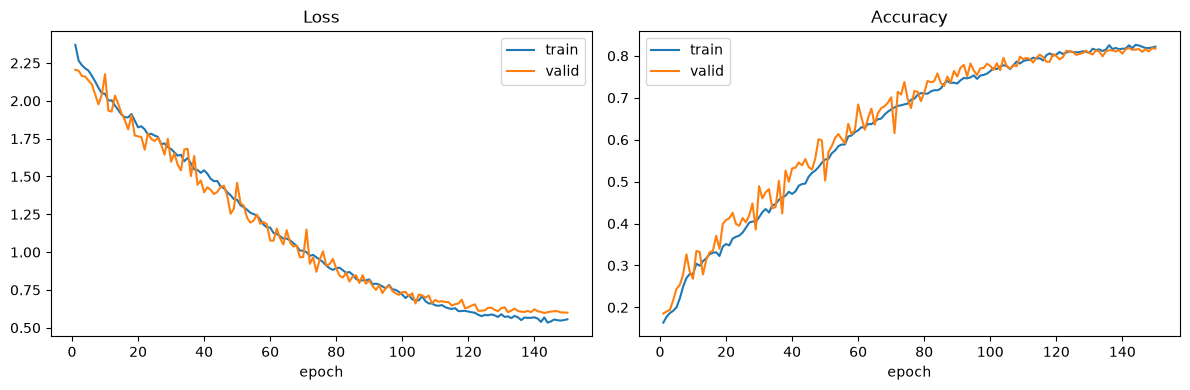

In [18]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["valid_loss"], label="valid")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["valid_acc"], label="valid")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"loss_6.png", dpi=150)
plt.show()